# Orbit Wars — PyTorch Geometric Graph Pipeline (Baştan Sona)

Bu notebook, **Kaggle Orbit Wars** ortamından gelen ham gözlemin nasıl `Observation` tensörlerine dönüştürüldüğünü, **graph metriklerinin** (`model_graph_pyg.py`) nasıl hesaplandığını ve sonuçların **PyTorch Geometric (PyG) GNN encoder + policy** (`PygPlanetGraphPolicy`) içine nasıl yerleştirildiğini adım adım anlatır.

| Aşama | Modül | Çıktı |
|-------|-------|-------|
| 1. Ham env | `kaggle_environments` | `planets`, `fleets`, `angular_velocity`, … |
| 2. Parse | `feature_extraction.py` | `Planet`, `Fleet` nesneleri |
| 3. Observation | `obs_builder.py` | `Observation` dataclass (padded numpy) |
| 4. Graph metrikler | `model_graph_pyg.py` | ETA matrisi, 8 node + 9 edge kanal |
| 5. Flux (opsiyonel) | `rl/flux.py` | 4 ek node kanalı (uçuşta filo akışı) |
| 6. PyG graph | `observation_to_pyg_data` | `torch_geometric.data.Data` |
| 7. Encoder | `PygPlanetGraphEncoder` | `node_tokens`, `graph_summary` |
| 8. Policy | `PygPlanetGraphPolicy` | `src_logits`, `tgt_logits`, `ship_params`, `value` |

**Not:** Notebook `docs/` altındadır; import path'i proje köküne (`..`) eklenir.


## Pipeline diyagramı

```
  env.reset/step
       │
       ▼
  feature_extraction.parse_planets / parse_fleets
       │
       ▼
  obs_builder.build_observation
       │  planet_feats (P,34)  fleet_feats (F,11)  global_feats (14)
       │  edge_bias (T,T,6)    masks + fleet routing arrays
       ▼
  ┌─────────────────────────────────────────────┐
  │  model_graph_pyg (deterministik, grad yok)  │
  │  • _estimated_intercept_eta_matrix          │
  │  • _graph_node_metrics  → 8 (+4 flux) kanal │
  │  • _graph_edge_metric_matrix → 9 kanal      │
  └─────────────────────────────────────────────┘
       │
       ▼
  observation_to_pyg_data / packed_observations_to_pyg_batch
       │  x: (n_real, 42 veya 46)   edge_index: (2, n*(n-1))
       │  edge_attr: (E, 15)         global_feats: (1, 14)
       ▼
  PygPlanetGraphEncoder (GINEConv × n_layers)
       │  node_tokens (n_real, d_model)
       │  graph_summary (1, d_model)
       ▼
  PygPlanetGraphPolicy heads
       src ~ Categorical   tgt ~ Categorical(src)
       ships ~ Beta(α,β)    value ~ scalar
       │
       ▼
  obs_builder.decode_action_with_launch → env action
```


### Ortam gereksinimleri

- Proje kökündeki Python paketleri (`obs_builder`, `model_graph_pyg`, …)
- **PyTorch Geometric** — `PygPlanetGraphEncoder` / `PygPlanetGraphPolicy` için zorunlu

```bash
# örnek (torch sürümünüze göre wheel seçin):
pip install torch torchvision
pip install torch_geometric
```

PyG yüklü değilse bölüm 1–10 (observation + graph metrikler) yine çalışır; bölüm 11+ hata verir.


## 1. Import'lar ve boyut sabitleri


In [64]:
import logging
logging.disable(logging.CRITICAL)

import os, sys
_workspace_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if _workspace_root not in sys.path:
    sys.path.insert(0, _workspace_root)

import numpy as np
import torch
%matplotlib inline
import matplotlib.pyplot as plt

from kaggle_environments import make
from feature_extraction import parse_planets, parse_fleets, Planet, Fleet
from navigation import compute_launch
from obs_builder import (
    build_observation, decode_action_with_launch,
    P_MAX_DEFAULT, F_MAX_DEFAULT, PLANET_FEATURE_DIM, FLEET_FEATURE_DIM,
    GLOBAL_FEATURE_DIM, EDGE_FEATURE_DIM,
    PF_IDX_OWNER_SELF, PF_IDX_SHIPS, PF_IDX_PRODUCTION,
    PF_IDX_R_SUN, PF_IDX_COS_THETA, PF_IDX_SIN_THETA,
)
from rl.flux import compute_flux_matrices, compute_node_flux_features, DEFAULT_FLUX_MODE
import importlib
import model_graph_pyg
importlib.reload(model_graph_pyg)  # PyG sonradan kurulduysa stale import'u temizler
from model_graph_pyg import (
    GRAPH_NODE_METRIC_DIM, GRAPH_NODE_FLUX_DIM, GRAPH_NODE_METRIC_DIM_FLUX,
    PYG_PLANET_FEATURE_DIM, PYG_PLANET_FEATURE_DIM_FLUX, PYG_EDGE_FEATURE_DIM,
    GRAPH_EDGE_METRIC_DIM,
    _estimated_intercept_eta_matrix, _graph_node_metrics, _graph_edge_metric_matrix,
    _planet_pair_edge_features, _planet_edge_index,
    observation_to_pyg_data, packed_observations_to_pyg_batch,
    PygPlanetGraphEncoder, PygPlanetGraphPolicy, pyg_nodes_to_padded,
    BilinearEdgeHead,
)
from model import pack_observations

try:
    from torch_geometric.data import Data, Batch
    PYG_OK = True
except ImportError as e:
    PYG_OK = False
    print("torch_geometric bulunamadı:", e)

print("PLANET_FEATURE_DIM      =", PLANET_FEATURE_DIM)
print("PYG_PLANET_FEATURE_DIM  =", PYG_PLANET_FEATURE_DIM, " (= raw + 8 graph node metrics)")
print("PYG_EDGE_FEATURE_DIM     =", PYG_EDGE_FEATURE_DIM, " (= 6 edge_bias + 9 graph edge metrics)")
print("P_MAX, F_MAX            =", P_MAX_DEFAULT, F_MAX_DEFAULT)
print("PyG available:", PYG_OK)



PLANET_FEATURE_DIM      = 34
PYG_PLANET_FEATURE_DIM  = 42  (= raw + 8 graph node metrics)
PYG_EDGE_FEATURE_DIM     = 15  (= 6 edge_bias + 9 graph edge metrics)
P_MAX, F_MAX            = 44 64
PyG available: True


## 2. Ortamı aç ve ham observation'ı incele

Orbit Wars observation'ı değişken uzunlukta listeler içerir. Agent kodu bunları **sabit boyutlu** tensörlere çevirir.


In [65]:
env = make("orbit_wars", debug=False)
env.configuration["randomSeed"] = 42
state = env.reset(num_agents=2)
state = env.step([[] for _ in range(2)])  # gezegenlerin spawn olması için boş adım

raw = state[0].observation
av = float(raw.get("angular_velocity", 0.0) or 0.0)
turn = int(raw.get("step", 0))

print("Ham observation anahtarları:", sorted(raw.keys()))
print(f"planets: {len(raw['planets'])} satır, örnek: {raw['planets'][0]}")
print(f"fleets:  {len(raw.get('fleets', []))} adet")
print(f"angular_velocity = {av:.4f}, step = {turn}")

# Bir launch zorla — flux / fleet routing demo için
from navigation import to_move
parsed_for_launch = parse_planets(raw)
mine_p = [p for p in parsed_for_launch if p.owner == 0]
others_p = [p for p in parsed_for_launch if p.owner != 0]
launch_move = None
for cand_src in mine_p:
    for cand_tgt in others_p:
        li = compute_launch(cand_src, cand_tgt, 10, parsed_for_launch, av)
        if li is not None:
            launch_move = to_move(li, cand_src)
            break
    if launch_move:
        break

if launch_move:
    state = env.step([[launch_move], []])  # env: her agent için move listesi
    raw = state[0].observation
    turn = int(raw.get("step", turn + 1))
    for _ in range(3):
        state = env.step([[], []])
    raw = state[0].observation
    print("Launch yapıldı; filo sayısı:", len(raw.get("fleets", [])))
else:
    print("Bu seed'de launch bulunamadı — pipeline yine de devam eder")



Ham observation anahtarları: ['angular_velocity', 'comet_planet_ids', 'comets', 'fleets', 'initial_planets', 'next_fleet_id', 'planets', 'player', 'remainingOverageTime', 'step']
planets: 28 satır, örnek: [0, 0, 98.82929298839605, 61.23941679953872, 1.0, 10, 1]
fleets:  0 adet
angular_velocity = 0.0420, step = 1
Launch yapıldı; filo sayısı: 1


## 3. `feature_extraction` — Planet ve Fleet nesneleri

Ham satırlar zengin dataclass'lara dönüşür:
- **Polar koordinat** (`r_sun`, `theta`) — rotasyonel simetri
- **Tip bayrakları** — `is_static`, `is_rotating`, `is_comet`
- **Fleet hızı** — env formülü: `v(s) = 1 + (v_max-1)·(ln s / ln 1000)^1.5`


In [66]:
planets = parse_planets(raw)
fleets = parse_fleets(raw)

p0 = planets[0]
print(p0)
print(f"  r_sun={p0.r_sun:.2f}, theta={p0.theta:.3f}, ships={p0.ships}, prod={p0.production}")
print(f"  is_static={p0.is_static}, is_rotating={p0.is_rotating}, is_comet={p0.is_comet}")

if fleets:
    f0 = fleets[0]
    print(f"\nFleet {f0.id}: owner={f0.owner}, ships={f0.ships}, speed={f0.speed:.2f}, from={f0.from_planet_id}")
else:
    print("\n(Uçuşta filo yok — yine de pipeline çalışır)")


Planet(id=0, owner=0, static, r=50.1, theta=+13deg, ships=4, prod=1)
  r_sun=50.11, theta=0.226, ships=4, prod=1
  is_static=True, is_rotating=False, is_comet=False

Fleet 0: owner=0, ships=10, speed=1.96, from=0


## 4. `build_observation` — RL Observation tensörleri

`build_observation(env_obs, player, omega)` şunları üretir:

| Alan | Shape | Açıklama |
|------|-------|----------|
| `planet_feats` | `(P_max, 34)` | Her gezegen slotu için normalize feature vektörü |
| `planet_mask` | `(P_max,)` | Gerçek gezegen = True |
| `fleet_feats` | `(F_max, 11)` | Uçuşta filo özellikleri |
| `fleet_mask` | `(F_max,)` | Aktif filo = True |
| `global_feats` | `(14,)` | Tur, omega, aggregate istatistikler |
| `edge_bias` | `(T,T,6)` | T = P_max + F_max + 1; pairwise geometri |
| `source_mask` | `(P_max,)` | Launch yapılabilir kendi gezegenler |
| `fleet_*_slot` | `(F_max,)` | Flux için routing (src/tgt slot, eta, ships) |


In [67]:
obs = build_observation(raw, player=0, angular_velocity=av, turn=turn)

print("Observation özeti:")
for name in [
    "planet_feats", "planet_mask", "fleet_feats", "fleet_mask",
    "global_feats", "edge_bias", "source_mask",
    "fleet_src_slot", "fleet_tgt_slot", "fleet_eta_raw",
]:
    arr = getattr(obs, name)
    extra = ""
    if name == "planet_mask":
        extra = f"  (real={int(arr.sum())})"
    if name == "fleet_mask":
        extra = f"  (active={int(arr.sum())})"
    print(f"  {name:18s} {tuple(arr.shape)}{extra}")

print("\nmeta:", obs.meta)


Observation özeti:
  planet_feats       (44, 34)
  planet_mask        (44,)  (real=28)
  fleet_feats        (64, 11)
  fleet_mask         (64,)  (active=1)
  global_feats       (14,)
  edge_bias          (109, 109, 6)
  source_mask        (44,)
  fleet_src_slot     (64,)
  fleet_tgt_slot     (64,)
  fleet_eta_raw      (64,)

meta: {'n_planets': 28, 'n_fleets': 1, 'incoming_self': 0, 'incoming_other': 0, 'p_max': 44, 'f_max': 64}


## 5. Planet feature vektörü (34 kanal)

İlk birkaç kanal (tam liste `obs_builder._planet_features`):

| idx | İsim | Anlam |
|-----|------|-------|
| 0 | owner_self | Bu gezegen bana mı ait |
| 1–3 | owner_enemy_* | Hangi düşman slotu |
| 4 | owner_neutral | Nötr mü |
| 5–7 | ships, production, radius | Normalize skalarlar |
| 8–10 | r_sun, cos θ, sin θ | Güneş merkezli polar |
| 11–13 | static / rotating / comet | Tip bayrakları |
| 14 | omega_dt | Açısal hız (rotating ise) |
| 16–23 | incoming ETA buckets | Gelen friendly/enemy gemiler |
| 24–33 | threat / capture / defense | Stratejik özet kanallar |


In [68]:
PLANET_CHANNEL_NAMES = [
    "owner_self", "enemy_0", "enemy_1", "enemy_2", "owner_neutral",
    "ships/100", "prod/5", "radius/5", "r_sun/50", "cos_theta", "sin_theta",
    "is_static", "is_rotating", "is_comet", "omega_dt", "log_ships",
    "inc_self_b0", "inc_self_b1", "inc_self_b2", "inc_self_b3",
    "inc_enemy_b0", "inc_enemy_b1", "inc_enemy_b2", "inc_enemy_b3",
    "inc_self_total", "inc_enemy_total", "self_min_eta", "enemy_min_eta",
    "enemy_soonest", "enemy_largest", "enemy_largest_eta",
    "net_threat", "capture_value", "defense_deficit",
]

real_idx = np.where(obs.planet_mask)[0][:3]
for slot in real_idx:
    pid = obs.planet_ids[slot]
    feats = obs.planet_feats[slot]
    print(f"\n--- planet slot {slot} (env id={pid}) ---")
    for i, (name, val) in enumerate(zip(PLANET_CHANNEL_NAMES, feats)):
        if abs(val) > 1e-4 or i < 15:
            print(f"  [{i:2d}] {name:22s} = {val:+.4f}")



--- planet slot 0 (env id=0) ---
  [ 0] owner_self             = +1.0000
  [ 1] enemy_0                = +0.0000
  [ 2] enemy_1                = +0.0000
  [ 3] enemy_2                = +0.0000
  [ 4] owner_neutral          = +0.0000
  [ 5] ships/100              = +0.0400
  [ 6] prod/5                 = +0.2000
  [ 7] radius/5               = +0.2000
  [ 8] r_sun/50               = +1.0021
  [ 9] cos_theta              = +0.9745
  [10] sin_theta              = +0.2243
  [11] is_static              = +1.0000
  [12] is_rotating            = +0.0000
  [13] is_comet               = +0.0000
  [14] omega_dt               = +0.0000
  [15] log_ships              = +0.2330
  [31] net_threat             = -0.0400

--- planet slot 1 (env id=1) ---
  [ 0] owner_self             = +0.0000
  [ 1] enemy_0                = +0.0000
  [ 2] enemy_1                = +0.0000
  [ 3] enemy_2                = +0.0000
  [ 4] owner_neutral          = +1.0000
  [ 5] ships/100              = +0.1200
  [ 6] prod/

## 6. Edge bias — geometrik pairwise sinyal

`edge_bias[i,j,:]` token `i` ile `j` arasındaki geometriyi kodlar (6 kanal):

0. normalize mesafe  
1–2. Δx, Δy  
3–4. sin/cos(Δφ) — yörünge açı farkı (rotating gezegenlerde zaman-invariant)  
5. `crosses_sun` — segment güneşe çarpıyor mu  

PyG graph yalnızca **planet–planet** alt matrisini kullanır: `edge_bias[:P, :P, :]`.


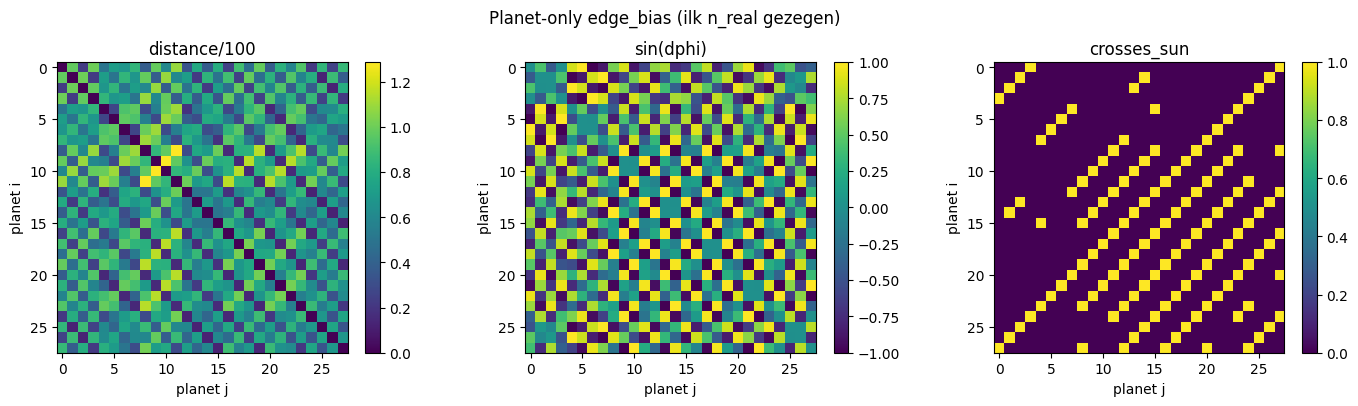

In [69]:
P = obs.planet_feats.shape[0]
eb_planet = obs.edge_bias[:P, :P, :]
n_real = int(obs.planet_mask.sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, ch, title in zip(axes, [0, 3, 5], ["distance/100", "sin(dphi)", "crosses_sun"]):
    mat = eb_planet[:n_real, :n_real, ch]
    im = ax.imshow(mat, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("planet j"); ax.set_ylabel("planet i")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("Planet-only edge_bias (ilk n_real gezegen)")
plt.tight_layout()
plt.show()


## 7. Intercept ETA matrisi — graph metriklerin temeli

`_estimated_intercept_eta_matrix` her `(kaynak i, hedef j)` çifti için **referans gemi sayısı (50)** ile intercept ETA hesaplar.

Algoritma özeti:
1. Hedef gezegenin `t = 0…50` tur boyunca konumunu grid'le
2. Kaynak konumundan doğrusal mesafe vs `speed × t` karşılaştır
3. İlk ulaşılabilir `t` = ETA; yoksa mesafe/hız fallback

Bu matris graph kernel'inde `exp(-eta/tau)` ile kullanılır (`tau=12` tur).


ETA matrisi shape: (28, 28)   (n_real, n_real)
min=0.0, max=41.0, mean=20.6


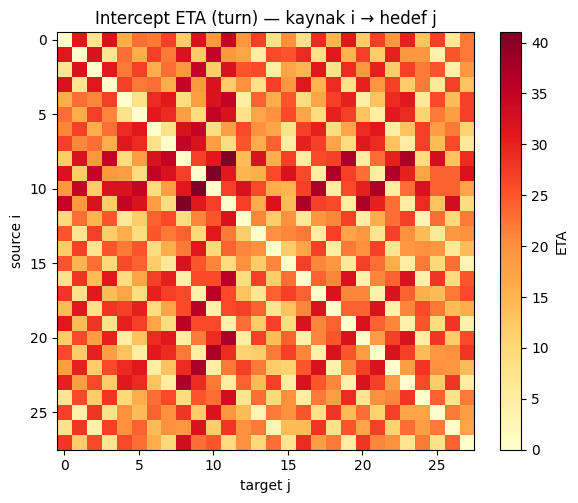

Influence kernel exp(-eta/12): diagonal=0 için destek matrisi ayrı sıfırlanır


In [70]:
planet_feats_t = torch.from_numpy(obs.planet_feats).float()
edge_bias_t = torch.from_numpy(obs.edge_bias).float()

eta = _estimated_intercept_eta_matrix(planet_feats_t, edge_bias_t, n_real)
print("ETA matrisi shape:", tuple(eta.shape), "  (n_real, n_real)")
print(f"min={eta.min():.1f}, max={eta.max():.1f}, mean={eta[eta>0].mean():.1f}")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(eta.numpy(), cmap="YlOrRd", vmin=0, vmax=min(50, eta.max().item()))
ax.set_title("Intercept ETA (turn) — kaynak i → hedef j")
ax.set_xlabel("target j"); ax.set_ylabel("source i")
plt.colorbar(im, ax=ax, label="ETA")
plt.tight_layout()
plt.show()

# Kernel örneği
kernel = torch.exp(-eta / 12.0)
print("Influence kernel exp(-eta/12): diagonal=0 için destek matrisi ayrı sıfırlanır")


## 8. Graph node metrikleri (8 kanal)

Her gezegen `g` için `_graph_node_metrics` şu vektörü üretir:

| # | Kanal | Formül (özet) |
|---|-------|----------------|
| 0 | friendly_influence | Σ_i friendly_ships_i · exp(-eta(i→g)/τ) |
| 1 | enemy_influence | Σ_i enemy_ships_i · exp(-eta(i→g)/τ) |
| 2 | influence_balance | friendly − enemy |
| 3 | friendly_support | diagonal sıfırlanmış kernel ile friendly |
| 4 | supportability | friendly_support / (enemy_influence + incoming_enemy + 1) |
| 5 | vulnerability | enemy_influence / (ships + incoming_friendly + 1) |
| 6 | production_potential | kernel-weighted production |
| 7 | strategic_potential | prod + friendly − enemy (ölçekli) |

Encoder girdisi: `cat(planet_feats, node_metrics)` → **42 boyut** (34+8).


node_metrics shape: (28, 8)


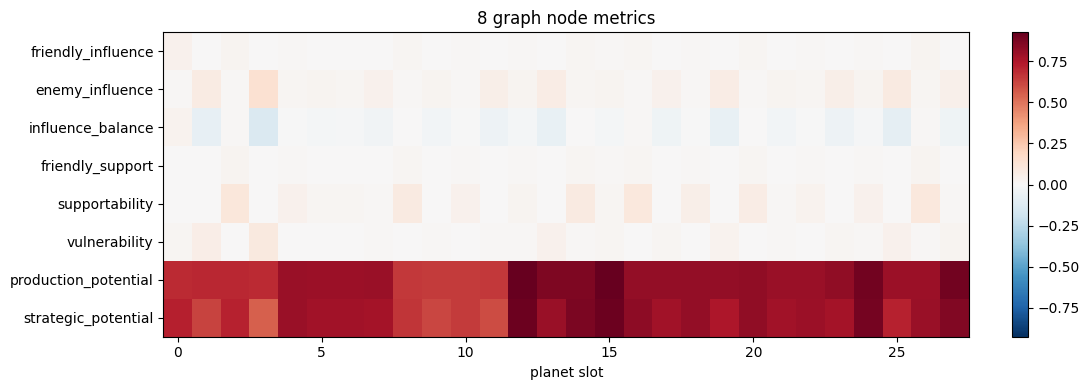

In [71]:
node_metrics = _graph_node_metrics(planet_feats_t, edge_bias_t, n_real, eta=eta)
NODE_NAMES = [
    "friendly_influence", "enemy_influence", "influence_balance",
    "friendly_support", "supportability", "vulnerability",
    "production_potential", "strategic_potential",
]
print("node_metrics shape:", tuple(node_metrics.shape))

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(node_metrics.numpy().T, aspect="auto", cmap="RdBu_r",
               vmin=-node_metrics.abs().max().item(), vmax=node_metrics.abs().max().item())
ax.set_yticks(range(8)); ax.set_yticklabels(NODE_NAMES)
ax.set_xlabel("planet slot"); ax.set_title("8 graph node metrics")
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout()
plt.show()


## 9. Graph edge metrikleri (9 kanal)

Her directed edge `(i→j)` için `_graph_edge_metric_matrix` 9 kanal üretir; bunlar `edge_bias`'ın 6 kanalına eklenir → **PYG_EDGE_FEATURE_DIM = 15**.

| # | Kanal |
|---|-------|
| 0 | eta_norm (ETA / 50) |
| 1 | movement_resistance (eta × (1+crosses_sun)) |
| 2 | same_owner |
| 3–6 | is_self_src, is_self_tgt, is_enemy_tgt, is_neutral_tgt |
| 7 | strategic_gradient (strategic_j − strategic_i) |
| 8 | flow_opportunity = relu(strategic_j − strategic_i) / (eta+1) |


In [72]:
edge_metrics = _graph_edge_metric_matrix(planet_feats_t, edge_bias_t, n_real, eta=eta, node_metrics=node_metrics)
EDGE_NAMES = [
    "eta_norm", "movement_resistance", "same_owner",
    "is_self_src", "is_self_tgt", "is_enemy_tgt", "is_neutral_tgt",
    "strategic_gradient", "flow_opportunity",
]
print("edge_metrics shape:", tuple(edge_metrics.shape))

# Tek bir (src, tgt) çifti detayı
src, tgt = 0, min(5, n_real - 1)
pair_full = _planet_pair_edge_features(planet_feats_t, edge_bias_t, n_real, eta=eta, node_metrics=node_metrics)
print(f"\nPlanet pair ({src} → {tgt}) — toplam {pair_full.shape[-1]} kanal:")
print("  [0:6]  base edge_bias:", pair_full[src, tgt, :6].numpy())
for k, name in enumerate(EDGE_NAMES):
    print(f"  [{6+k:2d}] {name:22s} = {pair_full[src, tgt, 6+k].item():+.4f}")


edge_metrics shape: (28, 28, 9)

Planet pair (0 → 5) — toplam 15 kanal:
  [0:6]  base edge_bias: [ 0.7147818  -0.6218791   0.35239097  0.99856204 -0.05360838  0.        ]
  [ 6] eta_norm               = +0.4600
  [ 7] movement_resistance    = +0.2300
  [ 8] same_owner             = +0.0000
  [ 9] is_self_src            = +1.0000
  [10] is_self_tgt            = +0.0000
  [11] is_enemy_tgt           = +0.0000
  [12] is_neutral_tgt         = +1.0000
  [13] strategic_gradient     = +0.0105
  [14] flow_opportunity       = +0.0022


## 10. Flux metrikleri (opsiyonel +4 kanal)

Uçuşta filolar planet-only graph'ta ayrı düğüm değildir; `rl/flux.py` bunları **yönlü akış matrisi** olarak kodlar:

- `M[i,j]` = slot `i`'den slot `j`'ye giden ağırlıklı gemi akışı
- Node flux: `[friendly_in, friendly_out, enemy_in, enemy_out]`

Flux açıkken node metrikler **12 kanal**, encoder girdisi **46 boyut** olur.


flux node features: (44, 4)
friendly flux matrix nonzero: 1
flux-augmented node metrics: (28, 12)


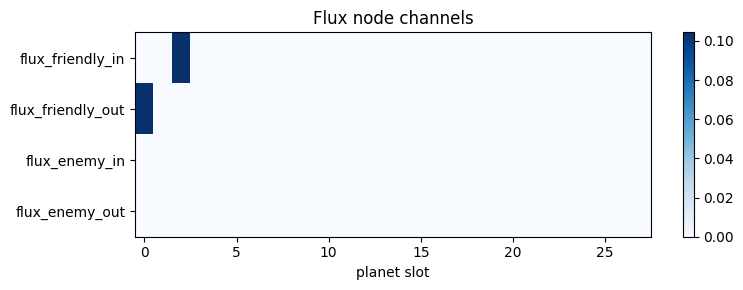

In [73]:
flux_feat = compute_node_flux_features(obs, mode=DEFAULT_FLUX_MODE)
flux_mat = compute_flux_matrices(obs, mode=DEFAULT_FLUX_MODE)

print("flux node features:", flux_feat.shape)
print("friendly flux matrix nonzero:", int((flux_mat.friendly > 0).sum()))

node_metrics_12 = _graph_node_metrics(
    planet_feats_t, edge_bias_t, n_real, eta=eta,
    flux_features=torch.from_numpy(flux_feat[:n_real]).float(),
)
print("flux-augmented node metrics:", tuple(node_metrics_12.shape))

FLUX_NAMES = ["flux_friendly_in", "flux_friendly_out", "flux_enemy_in", "flux_enemy_out"]
if np.abs(flux_feat[:n_real]).sum() > 0:
    fig, ax = plt.subplots(figsize=(8, 3))
    im = ax.imshow(flux_feat[:n_real].T, aspect="auto", cmap="Blues")
    ax.set_yticks(range(4)); ax.set_yticklabels(FLUX_NAMES)
    ax.set_xlabel("planet slot"); ax.set_title("Flux node channels")
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()
else:
    print("(Bu snapshot'ta aktif flux yok — launch sonrası tekrar deneyin)")


## 11. `observation_to_pyg_data` — Observation → PyG `Data`

Planet-only **tam bağlı directed graph** (self-loop yok):
- `n` gerçek gezegen → `n·(n-1)` directed edge
- `x`: `(n, 42)` — raw planet feats + 8 graph node metrics
- `edge_attr`: `(E, 15)` — geometric + graph edge metrics
- `global_feats`: `(1, 14)` — batch summary için


In [74]:
if not PYG_OK:
    raise ImportError(
        "torch_geometric yüklü değil. Terminalde:\n"
        "  orbit_wars_env/bin/pip install torch_geometric\n"
        "sonra bu notebook'un import hücresini yeniden çalıştırın."
    )

data = observation_to_pyg_data(obs)
print("PyG Data alanları:")
print(f"  x.shape           = {tuple(data.x.shape)}   # (n_real, {PYG_PLANET_FEATURE_DIM})")
print(f"  edge_index.shape  = {tuple(data.edge_index.shape)}  # (2, n*(n-1))")
print(f"  edge_attr.shape   = {tuple(data.edge_attr.shape)}")
print(f"  global_feats      = {tuple(data.global_feats.shape)}")
print(f"  planet_mask sum   = {int(data.planet_mask.sum())}")
print(f"  source_mask sum   = {int(data.source_mask.sum())}")

# x'in yapısı: ilk 34 ham, son 8 graph metric
x0 = data.x[0]
print(f"\nNode 0 feature breakdown:")
print(f"  raw planet feats [0:34]  norm={x0[:34].norm():.3f}")
print(f"  graph metrics [34:42]      = {x0[34:42].tolist()}")


PyG Data alanları:
  x.shape           = (28, 42)   # (n_real, 42)
  edge_index.shape  = (2, 756)  # (2, n*(n-1))
  edge_attr.shape   = (756, 15)
  global_feats      = (1, 14)
  planet_mask sum   = 28
  source_mask sum   = 1

Node 0 feature breakdown:
  raw planet feats [0:34]  norm=2.035
  graph metrics [34:42]      = [0.03999999910593033, 0.00972768198698759, 0.030272316187620163, 0.0, 0.0, 0.01945536397397518, 0.6919515132904053, 0.7222238779067993]


## 12. `PygPlanetGraphEncoder` — GINEConv mimarisi

Encoder üç aşamadan oluşur:

1. **Projeksiyon:** `LayerNorm → Linear → GELU` (node, edge, global ayrı)
2. **Message passing:** `n_layers` × `GINEConv`  
   - Her layer: `h_v ← h_v + MLP( Σ_{u→v} ReLU(h_u + W_e · e_{uv}) )`
   - Edge feature mesajla birlikte gider (GINE = Graph Isomorphism Network + Edge)
3. **Readout:** `global_mean_pool` + `global_max_pool` + `global_feats` → `graph_summary`

Çıktılar:
- `node_tokens`: `(n_real, d_model)` — policy head'lerine gider
- `graph_summary`: `(1, d_model)` — value head + global context


In [75]:
d_model, n_layers = 96, 2
encoder = PygPlanetGraphEncoder(d_model=d_model, n_layers=n_layers, enable_flux_features=False)
encoder.eval()

print(encoder)
print(f"\nParam count: {sum(p.numel() for p in encoder.parameters()):,}")

with torch.no_grad():
    enc_out = encoder(data)

print("\nEncoder çıktıları:")
print(f"  node_tokens.shape  = {tuple(enc_out['node_tokens'].shape)}")
print(f"  graph_summary.shape = {tuple(enc_out['graph_summary'].shape)}")


PygPlanetGraphEncoder(
  (node_proj): Sequential(
    (0): LayerNorm((42,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=42, out_features=96, bias=True)
    (2): GELU(approximate='none')
    (3): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  )
  (edge_proj): Sequential(
    (0): LayerNorm((15,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=15, out_features=96, bias=True)
    (2): GELU(approximate='none')
    (3): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  )
  (global_proj): Sequential(
    (0): LayerNorm((14,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=14, out_features=96, bias=True)
    (2): GELU(approximate='none')
    (3): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  )
  (convs): ModuleList(
    (0-1): 2 x GINEConv(nn=Sequential(
      (0): Linear(in_features=96, out_features=96, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=96, out_features=96, bias=True)
    ))

## 13. `PygPlanetGraphPolicy` — tam forward pass

Policy encoder'dan sonra **grouped planet** head yapısını kullanır:

| Head | Girdi | Çıktı | Anlam |
|------|-------|-------|-------|
| `src_head` | `[node_tok ∥ graph_summary]` | `(P_max,)` | Kaynak gezegen logits |
| `noop_head` | aynı | NO-OP logit | Hiç launch yapma |
| `pair_score_head` | Bilinear(src, tgt, edge, global) | `(P_max, P_max)` | Hedef logits |
| `ship_head` | Bilinear | `(P_max, P_max, 2)` | Beta α, β |
| `value_head` | `graph_summary` | scalar | PPO critic |

**Aksiyon faktörizasyonu:** `p(a|s) = p(src)·p(tgt|src)·p(ships|src,tgt)`


In [76]:
policy = PygPlanetGraphPolicy(d_model=d_model, n_layers=n_layers, enable_flux_features=False)
policy.eval()

# Tek obs → batch dim ekle
batch = pack_observations([obs])
with torch.no_grad():
    out = policy(**batch)

print("PolicyOutput:")
print(f"  src_logits   {tuple(out.src_logits.shape)}   # (B, P_max+1) incl. NO-OP dup")
print(f"  tgt_logits   {tuple(out.tgt_logits.shape)}   # (B, P_max, P_max)")
print(f"  ship_params  {tuple(out.ship_params.shape)}  # (B, P, P, 2) Beta α,β")
print(f"  value        {tuple(out.value.shape)}")
print(f"  tokens       {tuple(out.tokens.shape)}       # padded node embeddings")

# Maskelenmiş en iyi (src,tgt) çifti (demo)
src_l = out.src_logits[0, 1:1+obs.planet_mask.sum()]  # planet slots only
valid_src = torch.where(torch.from_numpy(obs.source_mask))[0]
if len(valid_src):
    best_src = valid_src[src_l[valid_src].argmax()]
    tgt_row = out.tgt_logits[0, best_src]
    tgt_row = tgt_row.masked_fill(~torch.from_numpy(obs.planet_mask), float('-inf'))
    best_tgt = tgt_row.argmax()
    print(f"\nGreedy demo: src_slot={best_src.item()}, tgt_slot={best_tgt.item()}")


PolicyOutput:
  src_logits   (1, 45)   # (B, P_max+1) incl. NO-OP dup
  tgt_logits   (1, 44, 44)   # (B, P_max, P_max)
  ship_params  (1, 44, 44, 2)  # (B, P, P, 2) Beta α,β
  value        (1,)
  tokens       (1, 44, 96)       # padded node embeddings

Greedy demo: src_slot=0, tgt_slot=14


## 14. GINEConv — tek layer'da mesaj akışı (intuition)

Bir `GINEConv` layer'da her kenar `(u→v)` şu mesajı taşır:

```
msg_{u→v} = MLP( h_u + W_e · e_{uv} )
h_v ← LayerNorm( h_v + Σ_{u∈N(v)} msg_{u→v} )
```

`e_{uv}` 15 boyutlu edge feature'dır (mesafe, ETA, strategic_gradient, …).  
Böylece model hem **komşu gezegen durumunu** hem **ulaşım maliyetini** aynı mesajda görür.


In [77]:
# Edge embedding boyutunu göster
edge_pair = policy.encoder.edge_proj(
    torch.from_numpy(
        np.zeros((1, P_MAX_DEFAULT, P_MAX_DEFAULT, PYG_EDGE_FEATURE_DIM), dtype=np.float32)
    )
)
print(f"edge_proj output shape (batch): {tuple(edge_pair.shape)}  → (B, P, P, d_model)")
print("Bu tensor pair_score_head ve ship_head tarafından paylaşılır.")


edge_proj output shape (batch): (1, 44, 44, 96)  → (B, P, P, d_model)
Bu tensor pair_score_head ve ship_head tarafından paylaşılır.


## 15. Flux-enabled policy (46-dim node input)

`enable_flux_features=True` ile encoder 46 kolon bekler; rollout `flux_features (B,P,4)` geçmelidir.


In [78]:
policy_flux = PygPlanetGraphPolicy(
    d_model=d_model, n_layers=n_layers, enable_flux_features=True,
)
policy_flux.eval()

flux_t = torch.from_numpy(flux_feat).float().unsqueeze(0)  # (1, P, 4)
with torch.no_grad():
    out_flux = policy_flux(**batch, flux_features=flux_t)

print("Flux policy forward OK")
print(f"  value = {out_flux.value.item():.4f}")


Flux policy forward OK
  value = 0.1732


## 16. Aksiyon örnekleme ve env'e decode

Policy continuous `ship_value ∈ [0,1]` üretir; `decode_action_with_launch` bunu env aksiyonuna çevirir (`navigation.compute_launch` açıyı çözer).


In [79]:
# PygPlanetGraphPolicy, GroupedPlanetOrbitWarsPolicy.act() kullanır
act_out = policy.act(out, deterministic=False)

src = act_out["src"][0].item()
tgt = act_out["tgt"][0].item()
ship_val = act_out["ship_value"][0].item()
print(f"Sampled: src_slot={src}, tgt_slot={tgt}, ship_value={ship_val:.3f}")
print(f"log_prob={act_out['log_prob'][0].item():.3f}, is_noop={act_out['is_noop'][0].item()}")

if act_out["is_noop"][0].item():
    print("NO-OP seçildi — decode atlanır")
else:
    action, info = decode_action_with_launch(
        obs, src_slot=src, tgt_slot=tgt,
        ship_value=ship_val, planets=planets, angular_velocity=av,
    )
    if action:
        print("Env action:", action)
        print("Launch info:", {k: info[k] for k in ['src_id','tgt_id','ships_sent','eta','overflow_ships'] if k in info})
    else:
        print("Decode başarısız (mask)")


Sampled: src_slot=0, tgt_slot=2, ship_value=0.805
log_prob=-2.978, is_noop=False
Env action: [0, -1.5707963267948966, 4]
Launch info: {'eta': 14.748918678177997, 'overflow_ships': 156.95409393310547}


## 17. Batch yolu — eğitimde kullanılan pipeline

Rollout sırasında `pack_observations` + `packed_observations_to_pyg_batch` bir mini-batch'i tek PyG `Batch` nesnesine birleştirir. Her graph ayrı `batch` index'i taşır.


In [80]:
obs2 = build_observation(raw, player=0, angular_velocity=av, turn=turn)
batch2 = pack_observations([obs, obs2])

graph_batch = packed_observations_to_pyg_batch(batch2)
print(f"Batch: num_graphs={graph_batch.num_graphs}, total nodes={graph_batch.x.shape[0]}")
print(f"       total edges={graph_batch.edge_index.shape[1]}")

with torch.no_grad():
    enc_b = encoder(graph_batch)
print(f"batched node_tokens: {tuple(enc_b['node_tokens'].shape)}")
print(f"batched graph_summary: {tuple(enc_b['graph_summary'].shape)}  # (B, d_model)")


Batch: num_graphs=2, total nodes=56
       total edges=1512
batched node_tokens: (56, 96)
batched graph_summary: (2, 96)  # (B, d_model)


## 18. Özet — boyut referans tablosu

| Tensor | Shape | Kaynak |
|--------|-------|--------|
| `planet_feats` | `(P_max, 34)` | `obs_builder` |
| `edge_bias` (planet block) | `(P_max, P_max, 6)` | geometri |
| ETA matrix | `(n_real, n_real)` | `_estimated_intercept_eta_matrix` |
| graph node metrics | `(n_real, 8)` veya `(n_real, 12)` | `_graph_node_metrics` |
| graph edge metrics | `(n_real, n_real, 9)` | `_graph_edge_metric_matrix` |
| PyG `x` | `(n_real, 42)` veya `(n_real, 46)` | raw + metrics (+ flux) |
| PyG `edge_attr` | `(n·(n-1), 15)` | 6 + 9 |
| `node_tokens` | `(n_real, d_model)` | GINEConv encoder |
| `src_logits` | `(B, P_max+1)` | policy |
| `tgt_logits` | `(B, P_max, P_max)` | policy |
| `ship_params` | `(B, P_max, P_max, 2)` | Beta head |
| `value` | `(B,)` | critic |

**İlgili dosyalar:** `obs_builder.py`, `model_graph_pyg.py`, `rl/flux.py`, `model_grouped_planet.py`, `rl/rollout.py`, `rl/train.py --model-variant pyg_planet_graph`.
